# Week 4 - Part D: the e-commerce review figure

Leadership looks at one dashboard every Monday. Right now the traffic is plotted raw (so the weekend rhythm hides the trend) and the catalogue is a multi-slice 3-D pie.
Plan: find every problem in `sessions_hourly.csv` and `revenue_catalogue.csv` first, write each one down with a rule and a count, and only then build the 2×2 figure.

This notebook also writes the cleaned daily series that Part B uses, so run it before Part B.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import to_rgb
import squarify

try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import tslib
from vizlib import PALETTE, style_defaults

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
SUB = ROOT / "submission"
CLEAN = DATA / "clean"
for p in (CHARTS, SUB, CLEAN):
    p.mkdir(exist_ok=True)

style_defaults()
warnings.filterwarnings("ignore", category=FutureWarning)
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK, SOFT = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]

LOG = []          # the cleaning log: one row per problem
def log(problem, rule, rows, before, after):
    LOG.append({"problem": problem, "rule": rule, "rows_affected": rows, "before": before, "after": after})

## 1. Inspect before touching anything
The four calls from the brief, in this order.

In [2]:
raw = pd.read_csv(DATA / "sessions_hourly.csv")
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12670 entries, 0 to 12669
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   ts           12670 non-null  str  
 1   sessions     12670 non-null  int64
 2   orders       12670 non-null  int64
 3   revenue_pkr  12670 non-null  int64
 4   device       12670 non-null  str  
dtypes: int64(3), str(2)
memory usage: 495.1 KB


In [3]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
sessions,12670.0,947.951381,646.882994,-1.0,435.0,756.0,1368.00,9811.0
orders,12670.0,30.016732,20.089492,4.0,14.0,24.0,42.00,304.0
revenue_pkr,12670.0,132564.968824,100150.706234,10350.0,58036.5,102359.0,182232.25,1652881.0


In [4]:
raw.device.value_counts()

device
Mobile     6994
Desktop    3452
mobile      883
Tablet      777
desktop     318
MOBILE      246
Name: count, dtype: int64

In [5]:
raw.ts.head(10).tolist()

['2024-04-29 11:00:00',
 '2024-10-26 05:00:00',
 '2025-08-04 20:00:00',
 '2024-10-05 19:00:00',
 '2025-01-22 20:00:00',
 '05/10/2024 09:00',
 '2024-08-11 15:00:00',
 '12/04/2025 10:00',
 '2024-07-24 02:00:00',
 '2025-03-27 11:00:00']

Four problems are already visible here:
1. `ts` is text, and it is written in **two formats** (`2024-04-29 11:00:00` and `05/10/2024 09:00`).
2. The rows are **not in time order** (April 2024, then October 2024, then August 2025 ...).
3. `device` has **six labels for three devices** (`Mobile` / `mobile` / `MOBILE`, `Desktop` / `desktop`, `Tablet`).
4. `sessions` has a **minimum of −1**. You can't have minus one visit, so it's a "no reading" sentinel.

## 2. The parse - and why `format="mixed"` is a trap

In [6]:
is_iso = raw.ts.str.match(r"^\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}$")
is_slash = raw.ts.str.match(r"^\d{2}/\d{2}/\d{4} \d{2}:\d{2}$")
print(f"ISO rows: {is_iso.sum():,}   slash rows: {is_slash.sum():,}   neither: {(~is_iso & ~is_slash).sum()}")

guess = pd.to_datetime(raw.ts, errors="coerce")
print(f"pd.to_datetime(ts) default: {guess.isna().sum():,} NaT")

mixed = pd.to_datetime(raw.ts, format="mixed")
print(f"format='mixed': 0 NaT, but the span is {mixed.min()} to {mixed.max()}  <- wrong")

first = raw.ts[is_slash].str.slice(0, 2).astype(int)
second = raw.ts[is_slash].str.slice(3, 5).astype(int)
print(f"slash rows with first field > 12: {(first > 12).sum():,};  with second field > 12: {(second > 12).sum()}")
iso_dt = pd.to_datetime(raw.ts[is_iso], format="%Y-%m-%d %H:%M:%S")
print(f"ISO rows alone span {iso_dt.min()} to {iso_dt.max()}")

ISO rows: 9,019   slash rows: 3,651   neither: 0
pd.to_datetime(ts) default: 3,651 NaT


format='mixed': 0 NaT, but the span is 2024-01-04 01:00:00 to 2025-12-08 22:00:00  <- wrong
slash rows with first field > 12: 2,151;  with second field > 12: 0
ISO rows alone span 2024-04-01 00:00:00 to 2025-09-11 23:00:00


The slash rows are **day-first**: the first field goes above 12 in 2,151 rows and the second field never does, so it can only be DD/MM. `format="mixed"` reads them month-first wherever it can, so "05/10/2024" becomes 10 May instead of 5 October. No row fails and no error is raised, but the series ends up stretched from January 2024 to December 2025.
Rule: parse each format explicitly, then check the span against the ISO rows (April 2024 to September 2025).

In [7]:
df = raw.copy()
df["dt"] = pd.NaT
df.loc[is_iso, "dt"] = pd.to_datetime(df.ts[is_iso], format="%Y-%m-%d %H:%M:%S")
df.loc[is_slash, "dt"] = pd.to_datetime(df.ts[is_slash], format="%d/%m/%Y %H:%M")
df["dt"] = pd.to_datetime(df.dt)
assert df.dt.notna().all()
print(f"parsed span: {df.dt.min()} to {df.dt.max()}")
n_moved = (mixed[is_slash] != df.dt[is_slash]).sum()
print(f"rows that format='mixed' would have put on the wrong date: {n_moved:,}")
log("ts in two formats (ISO and DD/MM/YYYY)", "parse each format explicitly; slash rows are day-first", int(is_slash.sum()),
    f"text; mixed-parse span {mixed.min():%Y-%m-%d} to {mixed.max():%Y-%m-%d}", f"datetime; span {df.dt.min():%Y-%m-%d} to {df.dt.max():%Y-%m-%d}")

parsed span: 2024-04-01 00:00:00 to 2025-09-11 23:00:00
rows that format='mixed' would have put on the wrong date: 1,382


## 3. Device labels

In [8]:
before_labels = df.device.nunique()
n_relabel = (~df.device.isin(["Mobile", "Desktop", "Tablet"])).sum()
df["device"] = df.device.str.strip().str.title()
print(df.device.value_counts().to_dict())
log("device written in 3 different cases", "strip + title-case", int(n_relabel), f"{before_labels} labels", f"{df.device.nunique()} labels")

{'Mobile': 8123, 'Desktop': 3770, 'Tablet': 777}


## 4. Now it is a DatetimeIndex: sort, then the two problems that only show up here

In [9]:
log("rows not in time order", "sort by parsed timestamp", int(len(df)), "unsorted", "monotonic increasing")
df = df.sort_values("dt", kind="stable")
idx = df.set_index("dt")
audit_raw = tslib.audit_index(idx, "h")
print({k: audit_raw[k] for k in ["dtype_ok", "monotonic", "n_rows", "n_duplicated", "n_missing", "span"]})

{'dtype_ok': True, 'monotonic': True, 'n_rows': 12670, 'n_duplicated': 286, 'n_missing': 312, 'span': ('2024-04-01 00:00:00', '2025-09-11 23:00:00')}


In [10]:
dups = idx[idx.index.duplicated(keep=False)]
same = dups.groupby(level=0)[["sessions", "orders", "revenue_pkr"]].nunique().max().max() == 1
print(f"duplicated timestamps: {idx.index.duplicated().sum()} extra rows; identical values within each pair: {same}")
mean_before = idx.sessions[idx.sessions >= 0].mean()
idx = idx[~idx.index.duplicated(keep="first")]
mean_after = idx.sessions[idx.sessions >= 0].mean()
log("duplicated timestamps (exact repeats, often one ISO + one slash copy)", "keep the first copy", int(audit_raw["n_duplicated"]),
    f"{audit_raw['n_rows']:,} rows; mean {mean_before:.1f} sessions/h", f"{len(idx):,} rows; mean {mean_after:.1f} sessions/h")

duplicated timestamps: 286 extra rows; identical values within each pair: True


In [11]:
full_hours = pd.date_range(idx.index.min(), idx.index.max(), freq="h")
missing = full_hours.difference(idx.index)
miss_days = pd.Series(missing.date).value_counts().sort_index()
print(f"missing hours: {len(missing)} = {len(miss_days)} whole days (24 h each: {bool((miss_days == 24).all())})")
print([str(d) for d in miss_days.index])
log("hours never recorded", "reindex onto a full hourly calendar; leave NaN so lines break; no interpolation", int(len(missing)),
    f"{len(idx):,} of {len(full_hours):,} hours", f"{len(missing)} NaN hours = {len(miss_days)} whole days")

missing hours: 312 = 13 whole days (24 h each: True)
['2024-05-18', '2024-07-02', '2024-07-03', '2024-09-27', '2024-11-11', '2024-12-25', '2025-01-01', '2025-02-14', '2025-03-30', '2025-03-31', '2025-06-07', '2025-07-19', '2025-08-23']


The 312 missing hours are 13 whole days. Pakistan has no daylight saving, so a missing day is a collector outage, not the clock changing. Counted here on the **hourly** index, before any resample (resampling would quietly bring those days back as rows).

## 5. The −1 sentinel

In [12]:
h = idx.sessions.reindex(full_hours)
sent = h.eq(-1)
h = h.where(~sent)
print(f"sentinel hours (after de-dup): {sent.sum()} on {h[sent].index.normalize().nunique()} days")
runs = sent.astype(int).groupby((~sent).cumsum()).sum()
print("sentinel run lengths:", runs[runs > 0].value_counts().to_dict())

has_prev = h.shift(1).notna() | h.shift(2).notna()
has_next = h.shift(-1).notna() | h.shift(-2).notna()
linear_ok = sent & has_prev & has_next
lin = h.interpolate(method="time", limit_area="inside")
week_fill = pd.concat([h.shift(168), h.shift(-168)], axis=1).mean(axis=1)

filled = h.copy()
filled[linear_ok] = lin[linear_ok]
edge = sent & ~linear_ok
filled[edge] = week_fill[edge]
print(f"filled by linear interpolation: {linear_ok.sum()}, by same hour ±7 days: {edge.sum()} ({list(h.index[edge].astype(str))})")
assert filled[sent].notna().all()
imputed = sent.copy()          # keep the flag

mean_with_sentinel = idx.sessions.mean()
log("sessions = -1 sentinel (no reading)", "set to NaN; fill the hour linearly from its neighbours (same hour ±7 days where a neighbour is a missing day); flag as imputed",
    int(sent.sum()), f"mean {mean_with_sentinel:.1f} sessions/h with -1 counted", f"mean {filled.mean():.1f} sessions/h")

sentinel hours (after de-dup): 287 on 222 days
sentinel run lengths: {1: 273, 2: 7}
filled by linear interpolation: 284, by same hour ±7 days: 3 (['2024-04-01 00:00:00', '2024-11-12 00:00:00', '2025-08-22 23:00:00'])


Almost all sentinels are single hours (273 single, 7 pairs), so filling from the neighbouring hours is a small, honest fix. The alternative (dropping them) would knock about 1/24 off 222 different days and add noise. Every filled hour is flagged, and the daily table below records how many filled hours each day contains.

## 6. Resample to daily - sessions is a flow, so `sum()`

In [13]:
daily = filled.resample("D").sum(min_count=24)          # a day counts only if all 24 hours exist
n_imputed = imputed.resample("D").sum()
print(f"days: {len(daily)}, NaN days: {daily.isna().sum()} (should be the 13 outage days)")
assert daily.isna().sum() == len(miss_days)
print(f"Black Friday 2024-11-29: {daily['2024-11-29']:,.0f} sessions")

a_daily = tslib.audit_index(daily.dropna(), "D")
print({k: a_daily[k] for k in ["n_rows", "n_duplicated", "n_missing", "partial_tail", "tail_period", "tail_count"]})

days: 529, NaN days: 13 (should be the 13 outage days)
Black Friday 2024-11-29: 113,710 sessions
{'n_rows': 516, 'n_duplicated': 0, 'n_missing': 13, 'partial_tail': True, 'tail_period': '2025-09', 'tail_count': 11}


In [14]:
print(f"extract ends {idx.index.max()} - September 2025 has {daily['2025-09'].notna().sum()} of 30 days")
log("partial final month (extract stops 11 Sep 2025)", "keep the 11 complete days in the daily chart, mark the end; never aggregate Sep-2025 as a month",
    int(daily['2025-09'].notna().sum()), "Sep-2025 as a month would be 11/30 of a month", "marked on panel 1; excluded from any monthly total")

out = pd.DataFrame({"sessions": daily, "imputed_hours": n_imputed})
out.index.name = "date"
out.to_csv(CLEAN / "sessions_daily_clean.csv")
print("saved", (CLEAN / "sessions_daily_clean.csv").relative_to(ROOT))

extract ends 2025-09-11 23:00:00 - September 2025 has 11 of 30 days
saved data/clean/sessions_daily_clean.csv


## 7. The catalogue: check it is a tree before drawing it

In [15]:
cat = pd.read_csv(DATA / "revenue_catalogue.csv")
print("rows:", len(cat), "| duplicated SKU ids:", cat.sku.duplicated().sum())
print(cat[cat.sku.duplicated(keep=False)][["category", "subcategory", "sku", "sku_name", "net_revenue_pkr_m"]])
print("net = revenue - returns everywhere:", np.allclose(cat.revenue_pkr_m - cat.returns_pkr_m, cat.net_revenue_pkr_m))
print("sub-categories with more than one parent:", (cat.groupby("subcategory").category.nunique() > 1).sum())

rows: 345 | duplicated SKU ids: 1
            category subcategory       sku sku_name  net_revenue_pkr_m
126  Audio & Imaging       Audio  SKU-0127  AUDI-04            14.8275
344        Lifestyle   Wearables  SKU-0127  AUDI-04            14.8275
net = revenue - returns everywhere: True
sub-categories with more than one parent: 0


SKU-0127 (`AUDI-04`) appears twice with identical numbers: once under Audio & Imaging / Audio, and once under Lifestyle / Wearables. Its name says Audio, so the Wearables row is the stray copy. A tree needs every child to have exactly one parent.

In [16]:
sh8 = pd.read_csv(DATA / "shares_eight.csv").set_index("subcategory").share_pct
def shares(frame):
    s = frame.groupby("subcategory").net_revenue_pkr_m.sum()
    return s / s.sum() * 100

dup_row = cat.index[(cat.sku == "SKU-0127") & (cat.subcategory == "Wearables")]
print(f"Wearables share, duplicate kept: {shares(cat)['Wearables']:.2f}%  vs file {sh8['Wearables']}%  (out by {shares(cat)['Wearables'] - sh8['Wearables']:+.2f} pts)")
cat_c = cat.drop(index=dup_row)
log("SKU-0127 listed under two parents (Audio and Wearables)", "keep the Audio row (sku_name AUDI-04); drop the Wearables copy", 1,
    f"Wearables {shares(cat)['Wearables']:.2f}% of net", f"Wearables {shares(cat_c)['Wearables']:.2f}% of net")

neg = cat_c[cat_c.net_revenue_pkr_m < 0]
print(f"\nSKUs with negative net revenue (returns > sales): {len(neg)}, total {neg.net_revenue_pkr_m.sum():.4f} PKR m")
print(neg[["subcategory", "sku", "sku_name", "revenue_pkr_m", "returns_pkr_m", "net_revenue_pkr_m"]].to_string(index=False))
pos = cat_c[cat_c.net_revenue_pkr_m >= 0]
log("7 SKUs with negative net revenue", "negatives have no area: kept out of the treemap and bar lengths, reported in the figure note", len(neg),
    f"net {cat_c.net_revenue_pkr_m.sum():.2f} PKR m incl. negatives", f"net {pos.net_revenue_pkr_m.sum():.2f} PKR m drawn; {neg.net_revenue_pkr_m.sum():.2f} shown as text")

Wearables share, duplicate kept: 10.13%  vs file 9.2%  (out by +0.93 pts)

SKUs with negative net revenue (returns > sales): 7, total -1.0693 PKR m
subcategory      sku sku_name  revenue_pkr_m  returns_pkr_m  net_revenue_pkr_m
Accessories SKU-0058  ACCE-18         0.0001         0.0002            -0.0001
     Drones SKU-0233  DRON-18         0.0495         0.1112            -0.0617
     Drones SKU-0242  DRON-27         0.0720         0.1239            -0.0519
  Wearables SKU-0272  WEAR-20         0.0882         0.1150            -0.0268
  Wearables SKU-0299  WEAR-47         0.2311         0.5350            -0.3039
   Footwear SKU-0335  FOOT-30         0.1368         0.2744            -0.1376
   Footwear SKU-0344  FOOT-39         0.3116         0.7989            -0.4873


In [17]:
check = pd.DataFrame({"mine": shares(pos).round(2), "shares_eight.csv": sh8})
check["diff_pts"] = (check["mine"] - check["shares_eight.csv"]).round(2)
print(check.sort_values("mine", ascending=False))
assert check.diff_pts.abs().max() < 0.3
print(f"\nself-check passed: max difference {check.diff_pts.abs().max():.2f} pts (needs < 0.3)")

              mine  shares_eight.csv  diff_pts
subcategory                                   
Phones       24.75              24.6      0.15
Laptops      18.22              18.4     -0.18
Audio        14.98              15.0     -0.02
Accessories  13.33              13.1      0.23
Footwear     10.99              11.2     -0.21
Wearables     9.36               9.2      0.16
Cameras       5.97               6.1     -0.13
Drones        2.41               2.4      0.01

self-check passed: max difference 0.23 pts (needs < 0.3)


In [18]:
sub = pos.groupby(["category", "subcategory"]).net_revenue_pkr_m.sum().reset_index()
total = sub.net_revenue_pkr_m.sum()
rolled, other_note = tslib.rollup_other(sub.set_index("subcategory").net_revenue_pkr_m, min_share_pct=1.0)
print("Other bucket:", other_note)
print(f"depth: {len(pos)} SKUs rolled up to {len(sub)} sub-categories in {sub.category.nunique()} categories")
assert abs(sub.groupby("category").net_revenue_pkr_m.sum().sum() - total) < 1e-9     # children sum to parents
cats = sub.groupby("category").net_revenue_pkr_m.sum().sort_values(ascending=False)
print((cats / total * 100).round(1))

Other bucket: no categories below 1.0%
depth: 337 SKUs rolled up to 8 sub-categories in 4 categories
category
Mobile             38.1
Audio & Imaging    23.4
Lifestyle          20.3
Computing          18.2
Name: net_revenue_pkr_m, dtype: float64


## 8. The cleaning log

In [19]:
log_df = pd.DataFrame(LOG)
log_df.to_csv(SUB / "partD_cleaning_log.csv", index=False)
log_df

,problem,rule,rows_affected,before,after
0,ts in two formats (ISO and DD/MM/YYYY),parse each format explicitly; slash rows are d...,3651,text; mixed-parse span 2024-01-04 to 2025-12-08,datetime; span 2024-04-01 to 2025-09-11
1,device written in 3 different cases,strip + title-case,1447,6 labels,3 labels
2,rows not in time order,sort by parsed timestamp,12670,unsorted,monotonic increasing
3,"duplicated timestamps (exact repeats, often on...",keep the first copy,286,"12,670 rows; mean 970.2 sessions/h","12,384 rows; mean 969.4 sessions/h"
4,hours never recorded,reindex onto a full hourly calendar; leave NaN...,312,"12,384 of 12,696 hours",312 NaN hours = 13 whole days
5,sessions = -1 sentinel (no reading),set to NaN; fill the hour linearly from its ne...,287,mean 946.9 sessions/h with -1 counted,mean 969.0 sessions/h
6,partial final month (extract stops 11 Sep 2025),"keep the 11 complete days in the daily chart, ...",11,Sep-2025 as a month would be 11/30 of a month,marked on panel 1; excluded from any monthly t...
7,SKU-0127 listed under two parents (Audio and W...,keep the Audio row (sku_name AUDI-04); drop th...,1,Wearables 10.13% of net,Wearables 9.35% of net
8,7 SKUs with negative net revenue,negatives have no area: kept out of the treema...,7,net 1711.38 PKR m incl. negatives,net 1712.45 PKR m drawn; -1.07 shown as text


## 9. Numbers for the titles

In [20]:
trend = daily.rolling(7, center=True, min_periods=7).mean()
m = daily.resample("MS").mean()
print("monthly mean of daily sessions:\n", m.round(0).to_string())
first_wk, peak_wk = trend.dropna().iloc[0], trend["2024-11-15":"2025-01-31"].max()
low_wk = trend["2025-03-01":"2025-07-15"].min()
low_date = trend["2025-03-01":"2025-07-15"].idxmin()
last_wk = trend.dropna().iloc[-1]
print(f"7-day mean: start {first_wk:,.0f}; winter high {peak_wk:,.0f}; spring low {low_wk:,.0f} on {low_date.date()}; end {last_wk:,.0f}")
print(f"start -> end: {last_wk / first_wk - 1:+.0%};  low -> end: {last_wk / low_wk - 1:+.0%}")

hourly_valid = h.dropna()
heat = hourly_valid.groupby([hourly_valid.index.dayofweek, hourly_valid.index.hour]).mean().unstack()
heat_no_bf = hourly_valid.drop(hourly_valid["2024-11-29"].index)
heat_no_bf = heat_no_bf.groupby([heat_no_bf.index.dayofweek, heat_no_bf.index.hour]).mean().unstack()
print(f"busiest cell: day {heat.stack().idxmax()}, {heat.max().max():,.0f}/h; quietest {heat.stack().idxmin()}, {heat.min().min():,.0f}/h")
print(f"weekend vs weekday mean per hour: {heat.loc[[5, 6]].mean().mean() / heat.loc[0:4].mean().mean() - 1:+.0%}")
print(f"Black Friday's pull on the Friday row: max cell change {(heat - heat_no_bf).abs().max().max():.0f} sessions/h")
bank = tslib.banked_figsize(trend.dropna().to_numpy(), width=7.0)
print(f"banked_figsize on the 7-day trend (width 7 in): {bank[0]:.2f} x {bank[1]:.2f} in  -> aspect h/w {bank[1] / bank[0]:.2f}")

monthly mean of daily sessions:
 2024-04-01    15513.0
2024-05-01    15276.0
2024-06-01    16546.0
2024-07-01    17948.0
2024-08-01    20320.0
2024-09-01    22933.0
2024-10-01    24978.0
2024-11-01    30021.0
2024-12-01    27734.0
2025-01-01    26965.0
2025-02-01    26066.0
2025-03-01    24942.0
2025-04-01    23205.0
2025-05-01    23013.0
2025-06-01    23728.0
2025-07-01    25209.0
2025-08-01    29008.0
2025-09-01    29793.0
Freq: MS
7-day mean: start 15,561; winter high 40,100; spring low 22,603 on 2025-05-14; end 30,958
start -> end: +99%;  low -> end: +37%


busiest cell: day (np.int32(5), np.int32(20)), 2,336/h; quietest (np.int32(2), np.int32(4)), 367/h
weekend vs weekday mean per hour: +35%
Black Friday's pull on the Friday row: max cell change 116 sessions/h
banked_figsize on the 7-day trend (width 7 in): 7.00 x 5.24 in  -> aspect h/w 0.75


## 10. The figure

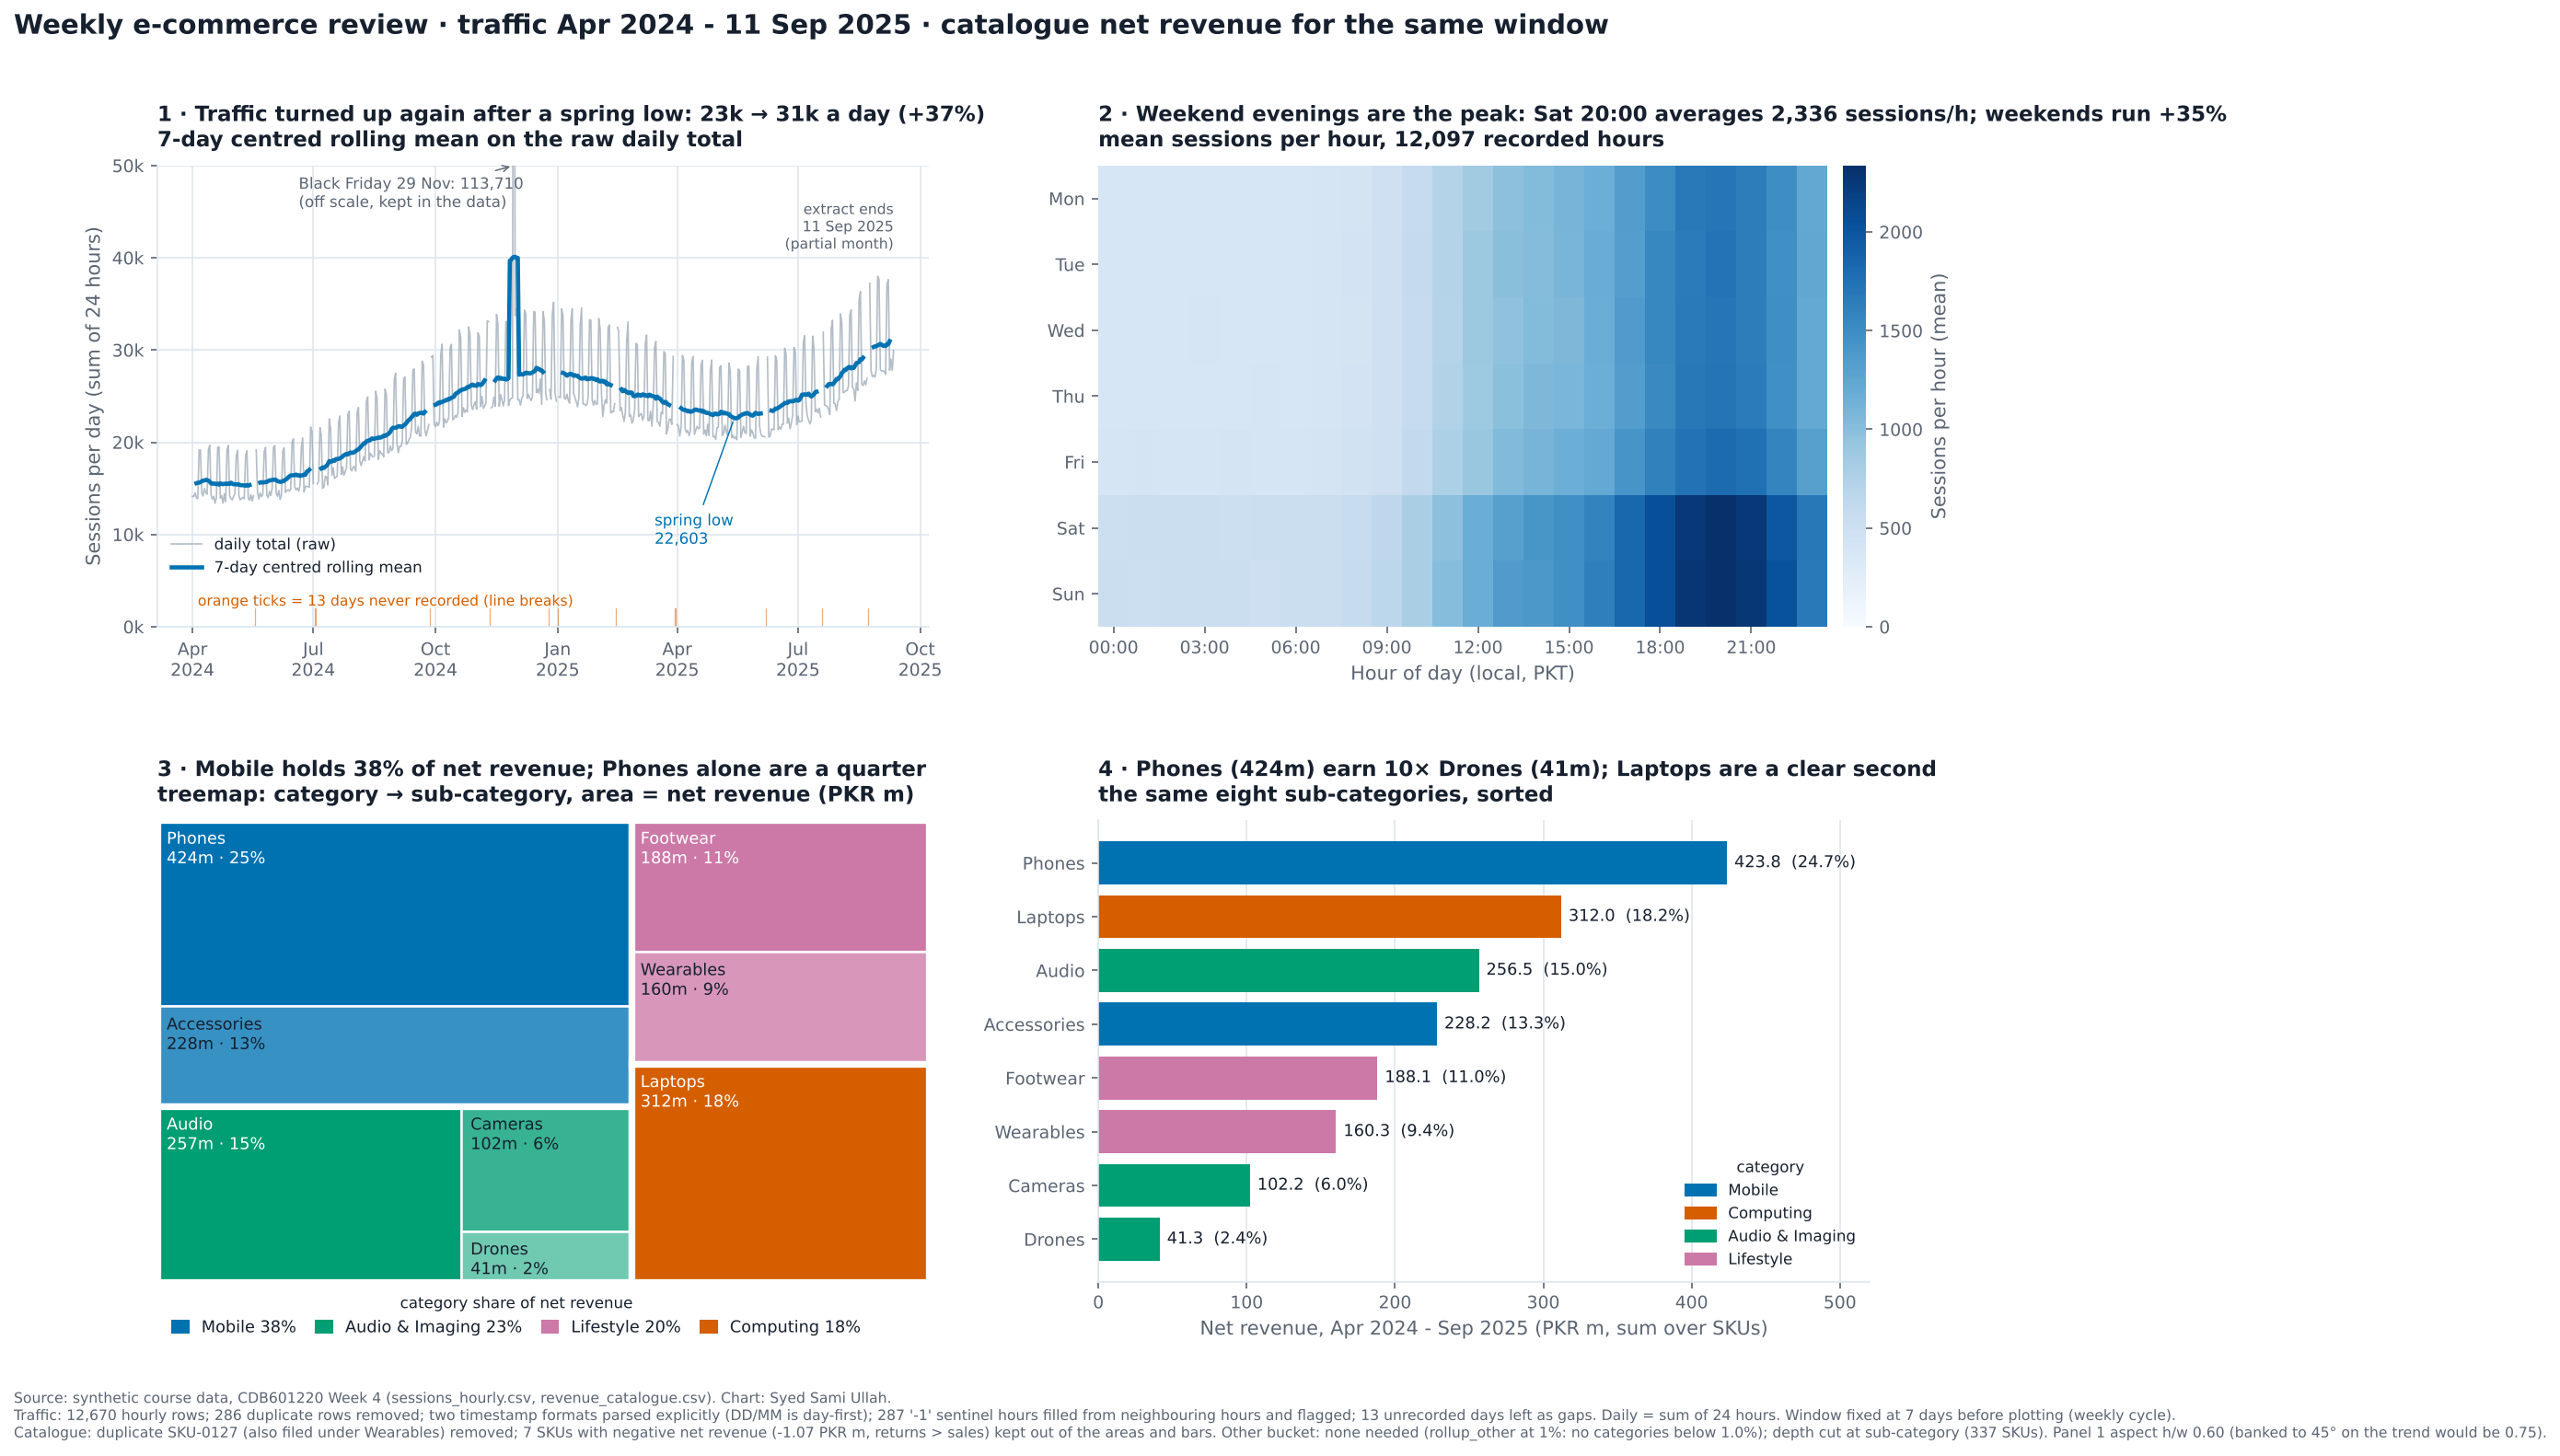

In [21]:
def tint(hex_colour, amount):
    """Mix a colour towards white; amount 0 = original."""
    r, g, b = to_rgb(hex_colour)
    return (r + (1 - r) * amount, g + (1 - g) * amount, b + (1 - b) * amount)

CAT_HUE = {"Mobile": BLUE, "Computing": ORANGE, "Audio & Imaging": GREEN, "Lifestyle": PINK}

fig, axes = plt.subplots(2, 2, figsize=(16, 10.5), gridspec_kw={"hspace": 0.42, "wspace": 0.22})
(ax1, ax2), (ax3, ax4) = axes

# --- panel 1: the daily series
ax1.plot(daily.index, daily, color=GREY, lw=0.8, alpha=0.75, label="daily total (raw)")
ax1.plot(trend.index, trend, color=BLUE, lw=2.2, label="7-day centred rolling mean")
for d in miss_days.index:
    ax1.axvline(pd.Timestamp(d), color=ORANGE, lw=0.6, alpha=0.5, ymax=0.04)
ax1.annotate("Black Friday 29 Nov: 113,710\n(off scale, kept in the data)", xy=(pd.Timestamp("2024-11-29"), 50000), xytext=(pd.Timestamp("2024-06-20"), 45500),
             fontsize=8, color=SOFT, arrowprops=dict(arrowstyle="->", color=SOFT, lw=0.7))
ax1.annotate(f"spring low\n{low_wk:,.0f}", xy=(low_date, low_wk), xytext=(low_date - pd.Timedelta(days=60), 9000),
             fontsize=8, color=BLUE, arrowprops=dict(arrowstyle="-", color=BLUE, lw=0.7))
ax1.text(daily.index.max(), 41000, "extract ends\n11 Sep 2025\n(partial month)", ha="right", fontsize=7.5, color=SOFT)
ax1.text(pd.Timestamp("2024-04-05"), 2300, "orange ticks = 13 days never recorded (line breaks)", fontsize=7.5, color=ORANGE)
ax1.set_ylim(0, 50000)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax1.set_ylabel("Sessions per day (sum of 24 hours)")
ax1.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax1.legend(loc="lower left", bbox_to_anchor=(0.0, 0.08), fontsize=8)
ax1.set_title(f"1 · Traffic turned up again after a spring low: {low_wk / 1000:.0f}k → {last_wk / 1000:.0f}k a day ({last_wk / low_wk - 1:+.0%})\n"
              "7-day centred rolling mean on the raw daily total", fontsize=11)

# --- panel 2: heatmap
im = ax2.imshow(heat.values, aspect="auto", cmap=PALETTE["sequential"], vmin=0)
ax2.set_yticks(range(7))
ax2.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax2.set_xticks(range(0, 24, 3))
ax2.set_xticklabels([f"{h:02d}:00" for h in range(0, 24, 3)])
ax2.set_xlabel("Hour of day (local, PKT)")
ax2.grid(False)
for s in ax2.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax2, fraction=0.035, pad=0.02)
cb.set_label("Sessions per hour (mean)", color=SOFT)
cb.outline.set_visible(False)
ax2.set_title(f"2 · Weekend evenings are the peak: Sat 20:00 averages {heat.max().max():,.0f} sessions/h; weekends run +35%\n"
              f"mean sessions per hour, {len(hourly_valid):,} recorded hours", fontsize=11)

# --- panel 3: nested treemap, one hue per parent category
ax3.set_xlim(0, 100); ax3.set_ylim(0, 100); ax3.invert_yaxis(); ax3.axis("off")
cat_rects = squarify.squarify(squarify.normalize_sizes(cats.values, 100, 100), 0, 0, 100, 100)
for (cname, cval), cr in zip(cats.items(), cat_rects):
    kids = sub[sub.category == cname].sort_values("net_revenue_pkr_m", ascending=False)
    kid_rects = squarify.squarify(squarify.normalize_sizes(kids.net_revenue_pkr_m.values, cr["dx"], cr["dy"]),
                                  cr["x"], cr["y"], cr["dx"], cr["dy"])
    for j, ((_, k), kr) in enumerate(zip(kids.iterrows(), kid_rects)):
        col = tint(CAT_HUE[cname], 0.22 * j)
        ax3.add_patch(plt.Rectangle((kr["x"], kr["y"]), kr["dx"], kr["dy"], facecolor=col, edgecolor="white", lw=1.2))
        txt_col = "white" if j == 0 else INK
        ax3.text(kr["x"] + 1.2, kr["y"] + 2, f"{k.subcategory}\n{k.net_revenue_pkr_m:,.0f}m · {k.net_revenue_pkr_m / total:.0%}",
                 fontsize=8.5, color=txt_col, va="top", ha="left")
    ax3.add_patch(plt.Rectangle((cr["x"], cr["y"]), cr["dx"], cr["dy"], fill=False, edgecolor="white", lw=3.5))
ax3.legend([plt.Rectangle((0, 0), 1, 1, color=CAT_HUE[c]) for c in cats.index],
           [f"{c} {v / total:.0%}" for c, v in cats.items()], loc="upper left", bbox_to_anchor=(0, 0.0),
           ncol=4, fontsize=8.5, handlelength=1, columnspacing=1.2, title="category share of net revenue", title_fontsize=8)
ax3.set_title(f"3 · Mobile holds {cats['Mobile'] / total:.0%} of net revenue; Phones alone are a quarter\n"
              "treemap: category → sub-category, area = net revenue (PKR m)", fontsize=11)

# --- panel 4: sorted bars, values printed
bars = sub.sort_values("net_revenue_pkr_m")
ax4.barh(bars.subcategory, bars.net_revenue_pkr_m, color=[CAT_HUE[c] for c in bars.category])
for i, (_, r) in enumerate(bars.iterrows()):
    ax4.text(r.net_revenue_pkr_m + 5, i, f"{r.net_revenue_pkr_m:,.1f}  ({r.net_revenue_pkr_m / total:.1%})", va="center", fontsize=8.5)
ax4.set_xlim(0, 520)
ax4.set_xlabel("Net revenue, Apr 2024 - Sep 2025 (PKR m, sum over SKUs)")
ax4.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in CAT_HUE.values()]
ax4.legend(handles, CAT_HUE.keys(), loc="lower right", fontsize=8, title="category", title_fontsize=8)
top, bottom = bars.iloc[-1], bars.iloc[0]
ax4.set_title(f"4 · Phones ({top.net_revenue_pkr_m:,.0f}m) earn {top.net_revenue_pkr_m / bottom.net_revenue_pkr_m:.0f}× Drones ({bottom.net_revenue_pkr_m:,.0f}m); "
              f"Laptops are a clear second\nthe same eight sub-categories, sorted", fontsize=11)

fig.suptitle("Weekly e-commerce review · traffic Apr 2024 - 11 Sep 2025 · catalogue net revenue for the same window",
             x=0.06, y=0.985, ha="left", fontsize=14, fontweight="bold")

fig.canvas.draw()
_bb = ax1.get_window_extent()
P1_ASPECT = _bb.height / _bb.width
note = ("Source: synthetic course data, CDB601220 Week 4 (sessions_hourly.csv, revenue_catalogue.csv). Chart: Syed Sami Ullah.\n"
        f"Traffic: 12,670 hourly rows; 286 duplicate rows removed; two timestamp formats parsed explicitly (DD/MM is day-first); {int(sent.sum())} '-1' sentinel hours filled from neighbouring hours and flagged; "
        f"{len(miss_days)} unrecorded days left as gaps. Daily = sum of 24 hours. Window fixed at 7 days before plotting (weekly cycle).\n"
        f"Catalogue: duplicate SKU-0127 (also filed under Wearables) removed; {len(neg)} SKUs with negative net revenue ({neg.net_revenue_pkr_m.sum():.2f} PKR m, returns > sales) "
        f"kept out of the areas and bars. Other bucket: none needed (rollup_other at 1%: {other_note}); depth cut at sub-category ({len(pos)} SKUs). Panel 1 aspect h/w {P1_ASPECT:.2f} (banked to 45° on the trend would be {bank[1] / bank[0]:.2f}).")
fig.text(0.06, 0.035, note, fontsize=7.5, color=SOFT, ha="left", va="top")

fig.savefig(SUB / "partD_figure.png", dpi=300, bbox_inches="tight", facecolor="white")      # savefig BEFORE show
fig.savefig(CHARTS / "partD_figure.png", dpi=300, bbox_inches="tight", facecolor="white")
show()

**What this figure shows.** Traffic grew through 2024, slid from the winter high to a spring low in May 2025, and has been climbing again since June, which is the seasonal turn the raw chart was hiding. Traffic peaks on weekend evenings, so that's when campaigns should go out. Mobile is the largest category, and the bars give the exact gaps the treemap can only hint at.

## 11. Appendix: 28-day window
Declared in Part E: does a longer window change the direction of the story?

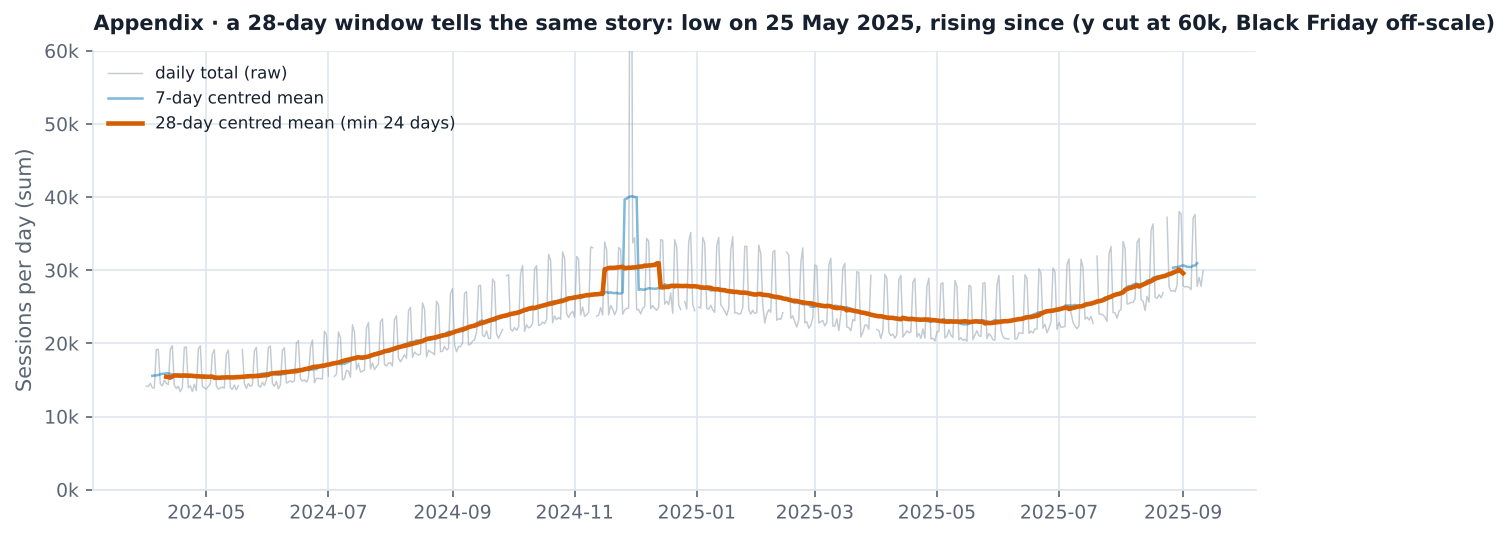

28-day low 22,727 on 2025-05-25; last 28-day value 29,585


In [22]:
t28 = daily.rolling(28, center=True, min_periods=24).mean()
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(daily.index, daily, color=GREY, lw=0.7, alpha=0.6, label="daily total (raw)")
ax.plot(trend.index, trend, color=BLUE, lw=1.2, alpha=0.5, label="7-day centred mean")
ax.plot(t28.index, t28, color=ORANGE, lw=2.2, label="28-day centred mean (min 24 days)")
ax.set_ylim(0, 60000)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f}k"))
ax.set_ylabel("Sessions per day (sum)")
ax.legend(loc="upper left", fontsize=8)
lo28 = t28["2025-03-01":"2025-07-15"].idxmin()
ax.set_title(f"Appendix · a 28-day window tells the same story: low on {lo28:%d %b %Y}, rising since (y cut at 60k, Black Friday off-scale)", fontsize=10)
fig.savefig(CHARTS / "partD_appendix_28day.png", dpi=300, bbox_inches="tight")
show()
print(f"28-day low {t28[lo28]:,.0f} on {lo28.date()}; last 28-day value {t28.dropna().iloc[-1]:,.0f}")

**What this shows.** The 28-day line puts the spring low within a few weeks of the 7-day one and shows the same rise after it. A longer window doesn't change the direction, it just smooths away the weekly ripple. The y axis is cut at 60k only so the trend is readable; this is a line chart, not bars, so the baseline rule doesn't apply.